# 03 - Localização da sonda

A partir só da imagem da câmera, queremos descobrir **onde a sonda está no mapa**.

- **ORB + homografia:** acha pontos marcantes na imagem e no mapa, casa os pontos parecidos e calcula como a imagem se encaixa no mapa.
- **Template matching:** desliza a imagem inteira sobre o mapa procurando o lugar mais parecido.

As imagens da câmera são recortes do mapa com posição, ângulo e altura conhecidos, por isso sabemos a resposta certa. Consideramos que o programa **acertou** quando o erro fica abaixo de 1 km.

In [1]:
import sys
sys.path.insert(0, "..")

import cv2
import matplotlib.pyplot as plt
import numpy as np

from pouso_lunar import config
from pouso_lunar.dados import carregar_mapa
from pouso_lunar.localizador import Localizador, localizar_template
from pouso_lunar.metricas import erro_km
from pouso_lunar.simulador import amostra_aleatoria, gerar_frame

config.PASTA_RESULTADOS.mkdir(exist_ok=True)
mapa, info = carregar_mapa()
L = mapa.shape[1]
orb = Localizador(mapa, "orb", cache=config.PASTA_DADOS / f"cache_orb_{L}.npz")
orb_sem_equalizar = Localizador(mapa, "orb", equalizar=False)
sift = Localizador(mapa, "sift", cache=config.PASTA_DADOS / f"cache_sift_{L}.npz")

# 300 imagens com posição, ângulo, altura, ruído e brilho sorteados (sempre as mesmas)
imagens = amostra_aleatoria(mapa, 300, config.SEMENTE)
print(f"{len(imagens)} imagens de teste")

300 imagens de teste


## Quantas imagens cada método acertou

In [2]:
def testar(nome, localizar):
    acertos, erros = 0, []
    for imagem, verdade in imagens:
        r = localizar(imagem, verdade)
        if r.ok:
            erro = erro_km(r.x, r.y, verdade.x, verdade.y, info.km_por_px)
            if erro < 1.0:
                acertos += 1
                erros.append(erro)
    tipico = f"erro típico de {np.median(erros) * 1000:.0f} m" if erros else ""
    print(f"{nome:22s} acertou {acertos} de {len(imagens)} ({acertos / len(imagens):.0%})  {tipico}")


testar("ORB", lambda img, v: orb.localizar(img))
testar("ORB sem equalizar", lambda img, v: orb_sem_equalizar.localizar(img))
testar("SIFT", lambda img, v: sift.localizar(img))
testar("Template matching", lambda img, v: localizar_template(mapa, img, v.zoom))

ORB                    acertou 224 de 300 (75%)  erro típico de 179 m


ORB sem equalizar      acertou 115 de 300 (38%)  erro típico de 152 m


SIFT                   acertou 226 de 300 (75%)  erro típico de 114 m


Template matching      acertou 4 de 300 (1%)  erro típico de 752 m


- O **ORB** acerta cerca de 3 em cada 4 imagens. O SIFT acerta parecido, mas é bem mais lento.
- **Equalizar o histograma** faz muita diferença: o mapa é escuro, e sem equalizar o ORB acerta só cerca da metade disso.
- O **template matching** quase nunca acerta, porque as imagens estão giradas.

## E se a imagem estiver girada?

Mesma posição, mudando só o ângulo da câmera.

In [3]:
x, y = L * 0.4, L * 0.7
for angulo in [0, 15, 45, 90, 180]:
    imagem, v = gerar_frame(mapa, x, y, angulo, 1.0)
    r_orb = orb.localizar(imagem)
    r_tpl = localizar_template(mapa, imagem, 1.0)
    ok_orb = r_orb.ok and erro_km(r_orb.x, r_orb.y, x, y, info.km_por_px) < 1
    ok_tpl = r_tpl.ok and erro_km(r_tpl.x, r_tpl.y, x, y, info.km_por_px) < 1
    print(f"{angulo:3d}°  ORB: {'acertou' if ok_orb else 'errou':8s}  Template: {'acertou' if ok_tpl else 'errou'}")

  0°  ORB: acertou   Template: acertou


 15°  ORB: acertou   Template: errou


 45°  ORB: acertou   Template: errou


 90°  ORB: acertou   Template: errou


180°  ORB: acertou   Template: errou


O ORB acerta com qualquer ângulo. O template só acerta com a imagem reta.

## Um exemplo

À esquerda, a imagem da câmera. À direita, o pedaço do mapa onde o programa achou a sonda (quadrado amarelo). As linhas verdes ligam os pontos que o ORB casou.

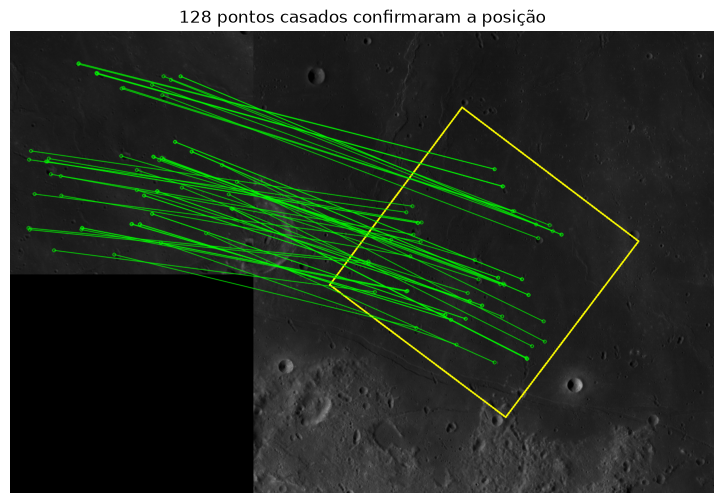

In [4]:
imagem, v = gerar_frame(mapa, L * 0.4, L * 0.7, 37, 1.1)
kp_img, desc_img = orb.det_frame.detectAndCompute(orb._prep(imagem), None)
pares = [m[0] for m in orb.matcher.knnMatch(desc_img, orb.desc, k=2)
         if len(m) == 2 and m[0].distance < config.RAZAO_LOWE * m[1].distance]
origem = np.float32([kp_img[m.queryIdx].pt for m in pares]).reshape(-1, 1, 2)
destino = orb.pts[[m.trainIdx for m in pares]].reshape(-1, 1, 2)
H, mascara = cv2.findHomography(origem, destino, cv2.RANSAC, config.LIMIAR_RANSAC_PX)
bons = mascara.ravel().astype(bool)

c = config.TAM_FRAME - 1
quadrado = cv2.perspectiveTransform(np.float32([[[0, 0], [c, 0], [c, c], [0, c]]]), H)[0]
x0, y0 = np.maximum(quadrado.min(0) - 150, 0).astype(int)
x1, y1 = np.minimum(quadrado.max(0) + 150, L).astype(int)
pedaco = cv2.cvtColor(mapa[y0:y1, x0:x1], cv2.COLOR_GRAY2BGR)
cv2.polylines(pedaco, [(quadrado - [x0, y0]).astype(np.int32)], True, (0, 255, 255), 2)
kp_a = [cv2.KeyPoint(float(p[0][0]), float(p[0][1]), 5) for p in origem[bons]]
kp_b = [cv2.KeyPoint(float(p[0][0] - x0), float(p[0][1] - y0), 5) for p in destino[bons]]
ligacoes = [cv2.DMatch(i, i, 0) for i in range(len(kp_a))][:60]
figura = cv2.drawMatches(cv2.cvtColor(imagem, cv2.COLOR_GRAY2BGR), kp_a, pedaco, kp_b, ligacoes, None,
                         matchColor=(0, 255, 0), flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
plt.figure(figsize=(12, 6))
plt.imshow(figura[..., ::-1])
plt.axis("off")
plt.title(f"{bons.sum()} pontos casados confirmaram a posição")
plt.savefig(config.PASTA_RESULTADOS / "localizacao_exemplo.png", dpi=110, bbox_inches="tight")
plt.show()